<a href="https://colab.research.google.com/github/ManuelSena25/Dental-Lesion-Detection/blob/main/06_Dental_Application.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Periapical Lesion Detection
This notebook combines a trained YOLO11 detector with SVM, ResNet50 and fine-tuned MobileNetV2. Upload one panoramic radiograph to obtain an annotated image and a comparison of PAI predictions for each detected region.
**Research prototype only.**

In [3]:
#Install the detector, interface and feature extraction libraries
!pip install -q ultralytics==8.4.215 gradio scikit-image

In [4]:
#Connect Google Drive to Colab
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

#Locate the project and trained models
PROJECT_DIR = Path("/content/drive/MyDrive/Dental_Lesion_Detection")
MODELS_DIR = PROJECT_DIR / "models"

Mounted at /content/drive


##Load models


In [5]:
import tensorflow as tf
import joblib
from ultralytics import YOLO
from tensorflow.keras.applications.resnet50 import preprocess_input

#Load YOLO to find possible lesions in the complete radiograph
detector = YOLO(str(MODELS_DIR / "yolo11_detection" / "weights" / "best.pt"))

#Load the SVM pipeline; its scaler is already included
svm = joblib.load(MODELS_DIR / "svm_model.pkl")

#Load ResNet50 with its original preprocessing function
resnet = tf.keras.models.load_model(
    MODELS_DIR / "resnet50.keras",
    custom_objects={"preprocess_input": preprocess_input},
    compile=False
)

#Load the fine-tuned MobileNetV2 classifier
mobilenet = tf.keras.models.load_model(
    MODELS_DIR / "mobilenet_v2_finetuned.keras",
    compile=False
)

print("All models loaded successfully")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.9.0 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator SVC from version 1.9.0 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator Pipeline from version 1.9.0 when using version 1.6.1. This might lead to breaking code or invalid results. 

All models loaded successfully


##Verify models


In [6]:
#Check that the saved models match our training configuration
print("YOLO11 classes:", detector.names)
print("SVM classes:", svm.classes_)
print("SVM input features:", svm.n_features_in_)
print("ResNet50 input:", resnet.input_shape)
print("MobileNetV2 input:", mobilenet.input_shape)

assert detector.names == {0: "PAI_3", 1: "PAI_4", 2: "PAI_5"}
assert list(svm.classes_) == [3, 4, 5]
assert svm.n_features_in_ == 1777
assert tuple(resnet.input_shape[1:]) == (128, 128, 3)
assert tuple(mobilenet.input_shape[1:]) == (128, 128, 3)

YOLO11 classes: {0: 'PAI_3', 1: 'PAI_4', 2: 'PAI_5'}
SVM classes: [3 4 5]
SVM input features: 1777
ResNet50 input: (None, 128, 128, 3)
MobileNetV2 input: (None, 128, 128, 3)


##Feature extraction
SVM uses the original 1,777 handcrafted features: 1,764 HOG values, 10 normalized LBP histogram values and 3 intensity statistics.

In [7]:
import numpy as np
from PIL import Image, ImageDraw, ImageFont
from skimage.feature import hog, local_binary_pattern

#Extract the same features used to train SVM
def extract_features(image):
    #Convert the lesion to grayscale and resize to 64 x 64 pixels
    image = image.convert("L").resize((64, 64))
    pixels = np.array(image)

    #Describe edges and shapes with HOG
    hog_features = hog(
        pixels, orientations=9,
        pixels_per_cell=(8, 8), cells_per_block=(2, 2)
    )

    #Describe local texture with LBP
    lbp = local_binary_pattern(pixels, P=8, R=1, method="uniform")
    lbp_hist, _ = np.histogram(lbp, bins=10, range=(0, 10))

    #Normalize the histogram to describe relative texture frequencies
    lbp_hist = lbp_hist.astype(float)
    lbp_hist /= lbp_hist.sum() + 1e-8

    #Measure the mean, standard deviation and median intensity
    statistics = [pixels.mean(), pixels.std(), np.median(pixels)]

    #Join the three types of features into one vector
    features = np.concatenate([hog_features, lbp_hist, statistics])
    return features

## 6. Dental X-ray analysis
YOLO detects possible lesions with a confidence threshold of 0.40. Each detected region is cropped and resized to 128 × 128 pixels without saving it as a new file.
The three classifiers analyze each region and predict its PAI class (3, 4 or 5). The CNN models use RGB pixel values from 0 to 255 because they already include preprocessing.
The results are displayed in a table to compare the predictions of each model. The application does not perform a clinical diagnosis.

In [8]:
import pandas as pd

#Define the columns and colors used to display the results
columns = ["Lesion", "YOLO11 PAI", "YOLO confidence (%)",
           "SVM PAI", "ResNet50 PAI", "MobileNetV2 PAI"]
colors = {3: "yellow", 4: "orange", 5: "red"}

#Analyze one complete panoramic radiograph
def analyze_xray(image):
    #Return an empty result if no image was uploaded
    if image is None:
        return None, 0, pd.DataFrame(columns=columns)

    #Convert the input to RGB and locate possible lesions
    image = image.convert("RGB")
    result = detector.predict(source=image, imgsz=1024,
                              conf=0.40, verbose=False)[0]

    #Draw on a copy so the original image remains unchanged
    output = image.copy()
    draw = ImageDraw.Draw(output)
    font = ImageFont.load_default(size=max(14, image.width // 100))
    records = []

    #Process each region detected by YOLO
    for box in result.boxes:
        #Read and clip the bounding box to the image boundaries
        x1, y1, x2, y2 = box.xyxy[0].int().tolist()
        x1 = max(0, x1)
        y1 = max(0, y1)
        x2 = min(image.width, x2)
        y2 = min(image.height, y2)

        #Ignore invalid or empty boxes
        if x2 <= x1 or y2 <= y1:
            continue

        #Crop the lesion using the original preparation size and filter
        crop = image.crop((x1, y1, x2, y2))
        crop = crop.resize((128, 128), Image.Resampling.LANCZOS)

        #Convert YOLO class indices 0, 1, 2 to PAI labels 3, 4, 5
        yolo_class = int(box.cls.item()) + 3
        confidence = float(box.conf.item()) * 100

        #Extract handcrafted features and classify with the SVM pipeline
        features = extract_features(crop)
        svm_class = int(svm.predict([features])[0])

        #Prepare a batch containing one RGB image for the neural networks
        pixels = np.array(crop, dtype=np.float32)
        pixels = np.expand_dims(pixels, axis=0)

        #Select the class with the highest predicted score for ResNet50
        resnet_scores = resnet.predict(pixels, verbose=0)
        resnet_class = int(np.argmax(resnet_scores[0])) + 3

        #Repeat the classification with fine-tuned MobileNetV2
        mobile_scores = mobilenet.predict(pixels, verbose=0)
        mobile_class = int(np.argmax(mobile_scores[0])) + 3

        #Assign a number to match each region with its table row
        lesion_id = len(records) + 1
        records.append([lesion_id, yolo_class, round(confidence, 2),
                        svm_class, resnet_class, mobile_class])

        #Draw the bounding box using the YOLO class color
        color = colors[yolo_class]
        draw.rectangle((x1, y1, x2, y2), outline=color, width=4)
        label = f"L{lesion_id} - PAI {yolo_class}"
        draw.text((x1, max(0, y1 - font.size - 2)), label,
                  fill=color, font=font, stroke_width=1, stroke_fill="black")

    #Return the annotated image, number of candidates and comparison table
    table = pd.DataFrame(records, columns=columns)
    return np.array(output), len(records), table

Saving stock-photo-original-panoramic-dental-x-ray-image-of-teeth-205753612.jpg to stock-photo-original-panoramic-dental-x-ray-image-of-teeth-205753612.jpg


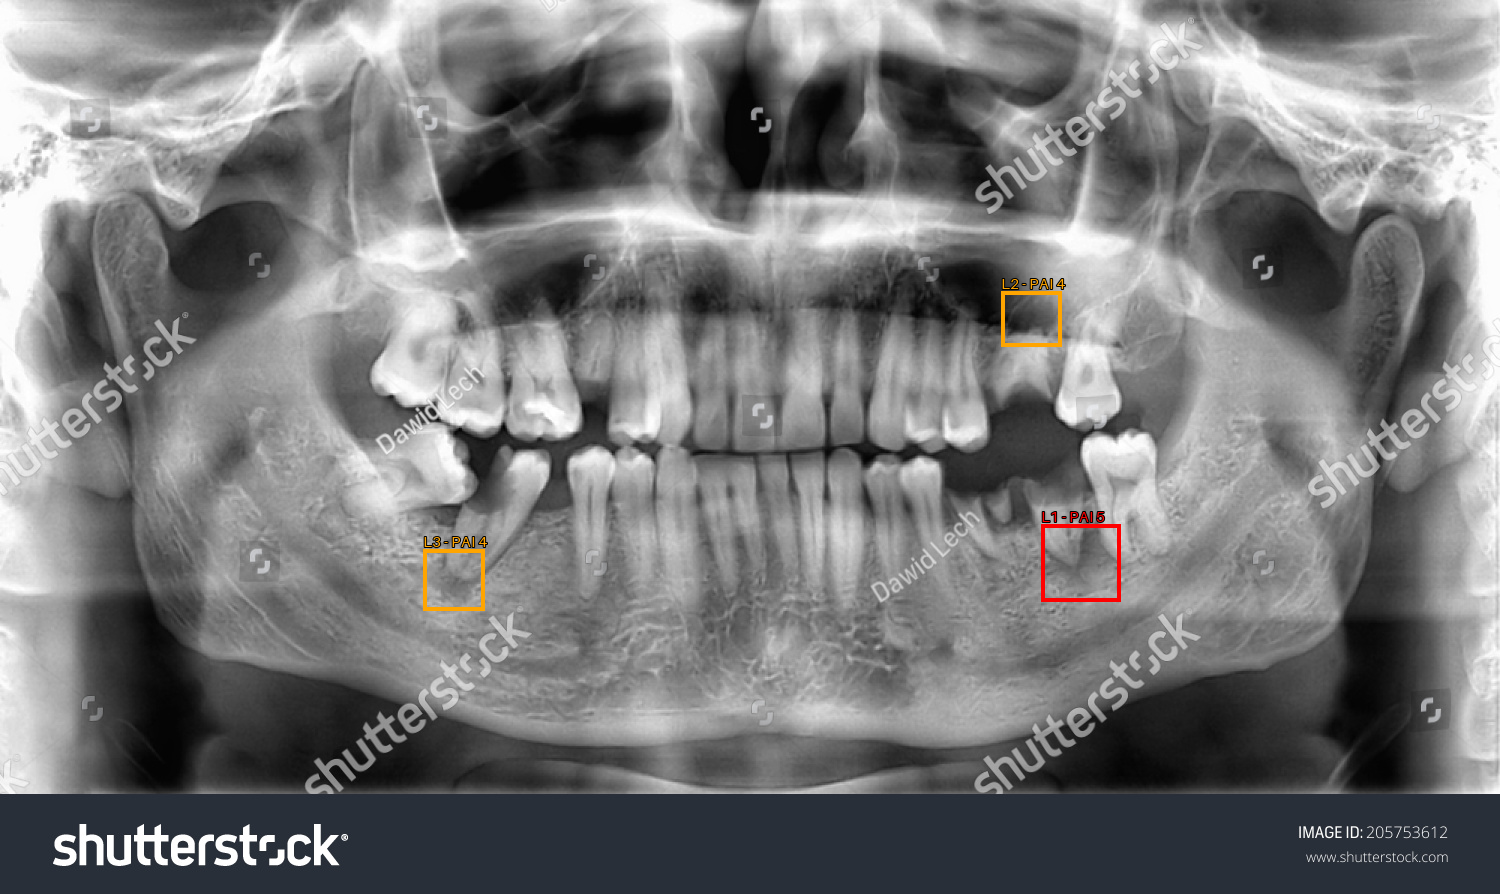

,Lesion,YOLO11 PAI,YOLO confidence (%),SVM PAI,ResNet50 PAI,MobileNetV2 PAI
0,1,5,53.82,4,4,4
1,2,4,47.73,3,3,4
2,3,4,44.19,4,3,4


In [9]:
#Test image results without Gradio

from google.colab import files
from PIL import Image
from IPython.display import display

uploaded = files.upload()

image_path = next(iter(uploaded))
image = Image.open(image_path).convert("RGB")

result_image, total, table = analyze_xray(image)

display(Image.fromarray(np.array(result_image)))
display(table)

##Application interface
Upload a panoramic JPG or PNG and press **Submit**. The confidence column belongs to YOLO only. A zero count means no regions passed the detection threshold, not that the patient is healthy.


In [12]:
#Import libraries
import gradio as gr
import base64
import io

#Prepare results for the interface
def show_results(image):

    #Analyze the X-ray
    result, total, table = analyze_xray(image)

    if result is None:
        return "", total, table

    #Convert result to an image
    result = Image.fromarray(np.array(result))

    #Store image in memory
    buffer = io.BytesIO()
    result.save(buffer, format="PNG")

    #Convert image to Base64
    encoded = base64.b64encode(buffer.getvalue()).decode()

    #Display image directly
    html = f'<img src="data:image/png;base64,{encoded}" width="100%">'

    return html, total, table


#Create application
app = gr.Interface(
    fn=show_results,

    inputs=gr.Image(
        type="pil",
        label="Upload panoramic X-ray"
    ),

    outputs=[
        gr.HTML(label="Detection results"),
        gr.Number(label="Potential lesions"),
        gr.Dataframe(label="Model predictions")
    ],

    title="Dental APP",
    description="Research prototype only. Not for clinical diagnosis."
)

#Launch application
app.launch(share=False, inline=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
Note: opening Chrome Inspector may crash demo inside Colab notebooks.
* To create a public link, set `share=True` in `launch()`.


<IPython.core.display.Javascript object>

In [11]:
#Close previous Gradio applications
gr.close_all()

Closing server running on port: 7861
Closing server running on port: 7860
Closing server running on port: 7862


## Limitations
The classifiers were evaluated on annotated lesion crops, not on YOLO-generated crops. The combined system requires independent external annotated radiographs for quantitative evaluation. Individual predictions and YOLO confidence do not establish a clinical diagnosis.

##External Image Testing

The developed application integrates YOLO11, SVM, ResNet50, and Fine-Tuned MobileNetV2 to automatically detect and classify potential lesions in panoramic X-rays.

During external image testing, some predictions showed agreement across all four models, while other cases presented differences in the predicted severity levels.

Relatively low detection confidence scores were also observed, highlighting the limitations of the object detection stage.

These experiments demonstrate the functionality of the integrated system while providing examples of its limitations under new imaging conditions.

Since the external radiographs did not contain verified expert annotations, these results represent a qualitative evaluation rather than a clinical performance assessment.

This application should therefore be considered a research prototype and not a diagnostic tool.